# Estimating the noise spectrum

When the noise spectrum of the detectors is not known, it can be estimated
from the data: a first map with a guess (here white noise), the residual
$d - P\hat m$ of each detector, its averaged periodogram, and a second map
with the estimated spectrum. {func}`~pysanepic.estimate_noise` returns a
`TabulatedNoise` per detector (`DetectorData.name` groups the stretches of
time of a detector), or a fitted `OneOverFNoise` with `fit="toast"` or
`"keshner"`.

Here: 3 detectors without litebird_sim, a smooth sky, 1/f noise with
$f_\text{knee}$ = 0.1 Hz, α = 1.5, $f_\text{min}$ = 1 mHz.

In [1]:
import dataclasses

import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
from pysanepic import DetectorData, GLSParameters, OneOverFNoise, Pointing, estimate_noise, make_maps

nside, fs, chunk, nchunk = 16, 10.0, 4000, 40
net = 50.0
sigma = net * np.sqrt(fs) * 1e-6
true = OneOverFNoise(net_ukrts=net, fknee_hz=0.1, alpha=1.5, fmin_hz=1e-3)
psd_true = lambda f: 2 * sigma**2 / fs * (f**1.5 + 0.1**1.5) / (f**1.5 + 1e-3**1.5)
rng = np.random.default_rng(1)
sky = hp.smoothing(rng.normal(0, 1e-4, (3, 12 * nside**2)), fwhm=np.radians(8))


def scan(n):
    t = np.arange(n)
    lam = 2 * np.pi * t / n + rng.uniform(0, 2 * np.pi)
    spin = 2 * np.pi * t / 3000.0
    a = np.array([np.cos(lam), np.sin(lam), np.zeros(n)])
    z = np.array([np.zeros(n), np.zeros(n), np.ones(n)])
    e2 = np.cross(a.T, z.T).T
    b = np.cos(1.3) * a + np.sin(1.3) * (np.cos(spin) * z + np.sin(spin) * e2)
    return np.arccos(np.clip(b[2], -1, 1)), np.arctan2(b[1], b[0]) % (2 * np.pi), (spin + lam) % (2 * np.pi)


data = []
f = np.fft.rfftfreq(chunk, 1 / fs)
for j, pa in enumerate((0.0, np.pi / 4, np.pi / 8)):
    n = nchunk * chunk
    th, ph, psi = scan(n)
    a, p = psi + pa, hp.ang2pix(nside, th, ph)
    noise = np.concatenate([np.fft.irfft(np.fft.rfft(rng.normal(size=chunk)) * np.sqrt(psd_true(np.maximum(f, 1e-9)) * fs / 2), n=chunk)
                            for _ in range(nchunk)])  # one realization per chunk, with PSD psd_true
    tod = sky[0, p] + sky[1, p] * np.cos(2 * a) + sky[2, p] * np.sin(2 * a) + noise
    for s0 in range(0, n, 4 * chunk):  # stretches of time of the same detector
        sl = slice(s0, s0 + 4 * chunk)
        data.append(DetectorData(tod=tod[sl], pointing=Pointing(theta=th[sl], phi=ph[sl], psi=psi[sl], coordinates="E"),
                                 sampling_rate_hz=fs, noise=OneOverFNoise(net_ukrts=net), pol_angle_rad=pa, name=f"det{j}"))
params = GLSParameters(chunk_s=chunk / fs, tol=1e-10)

A first map with white noise, the estimated spectra, and a fit.

det0: NET 49.8 uK sqrt(s), fknee 0.116 Hz, alpha 1.22 (true: 50, 0.1, 1.5)
det1: NET 51.0 uK sqrt(s), fknee 0.106 Hz, alpha 1.43 (true: 50, 0.1, 1.5)
det2: NET 50.2 uK sqrt(s), fknee 0.112 Hz, alpha 1.28 (true: 50, 0.1, 1.5)


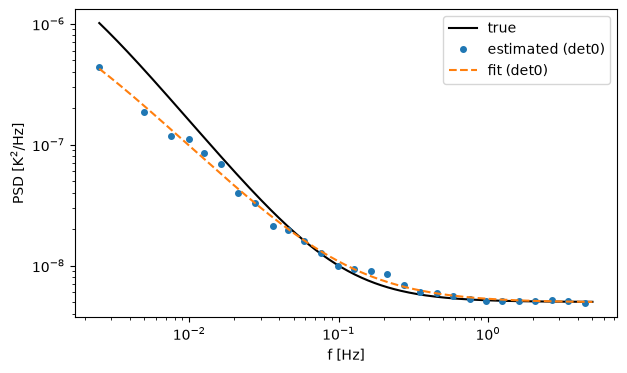

In [2]:
first = make_maps(data, nside, coordinates="E", params=params)
est = estimate_noise(data, first, chunk_s=chunk / fs, nbins=30)
fit = estimate_noise(data, first, chunk_s=chunk / fs, nbins=30, fit="toast")
for name, n in fit.items():
    print(f"{name}: NET {n.net_ukrts:.1f} uK sqrt(s), fknee {n.fknee_hz:.3f} Hz, alpha {n.alpha:.2f} (true: 50, 0.1, 1.5)")

fig, ax = plt.subplots(figsize=(7, 4))
fg = np.geomspace(1 / (chunk / fs), fs / 2, 300)
ax.loglog(fg, psd_true(fg), "k", label="true")
ax.loglog(est["det0"].freqs_hz, est["det0"].psd, "o", ms=4, label="estimated (det0)")
n0 = fit["det0"]
s0 = n0.net_ukrts * np.sqrt(fs) * 1e-6
ax.loglog(fg, 2 * s0**2 / fs * (fg**n0.alpha + n0.fknee_hz**n0.alpha) / (fg**n0.alpha + n0.fmin_hz**n0.alpha), "--", label="fit (det0)")
ax.set_xlabel("f [Hz]")
ax.set_ylabel("PSD [K$^2$/Hz]")
ax.legend()
plt.show()

The estimate follows the true spectrum, except between the spin frequency
(3.3 mHz) and the frequency at which the pixels are crossed (~0.3 Hz), where
the map absorbs part of the noise: this test scan is very repetitive (see *Estimating the noise* in the
usage page). Maps with the
estimated spectrum are compared with those with the true and the white noise
models:

In [3]:
seen = first.maps[1] != hp.UNSEEN
for label, noise in (("white", None), ("estimated", est), ("true", true)):
    d = data if noise is None else [dataclasses.replace(x, noise=noise[x.name] if isinstance(noise, dict) else noise) for x in data]
    r = first if noise is None else make_maps(d, nside, coordinates="E", params=params)
    err = (r.maps - sky)[:, seen] * 1e6
    print(f"{label:10s} noise model: {r.iterations:3d} iterations, rms error I/Q/U {err[0].std():.2f} / {err[1].std():.2f} / {err[2].std():.2f} uK")

white      noise model:   1 iterations, rms error I/Q/U 114.73 / 122.55 / 131.97 uK


estimated  noise model:  39 iterations, rms error I/Q/U 54.97 / 57.71 / 59.08 uK


true       noise model:  61 iterations, rms error I/Q/U 52.80 / 56.62 / 58.11 uK


The maps with the estimated spectrum are as good as those with the true one,
and much better than with white noise.